# **bước 3.3**

In [2]:
# -*- coding: utf-8 -*-

"""
Bước 1: đọc tệp dữ liệu và nhìn qua một lượt.

Chú thích trong tệp viết tiếng Việt có dấu, nhưng phần in ra màn hình cố ý
viết không dấu. Cửa sổ lệnh Windows thường không hiện được chữ có dấu.
"""

import pandas as pd

# Đọc tệp CSV thành một bảng. Tên df là viết tắt quen dùng của data frame.
df = pd.read_csv("gia_nha.csv")

print("Kich thuoc bang (so dong, so cot):", df.shape)
print()

print("Nam dong dau tien:")
print(df.head())
print()

print("Ten cac cot:", list(df.columns))
print()

print("Thong ke nhanh cot dien_tich va cot gia:")
print(df[["dien_tich", "gia"]].describe().round(2))
print()

print("So o bi thieu trong tung cot:")
print(df.isna().sum())

Kich thuoc bang (so dong, so cot): (60, 4)

Nam dong dau tien:
   dien_tich  so_phong  tuoi_nha   gia
0       35.5         1        18  3.00
1       37.6         2         7  3.87
2       49.4         2        20  4.25
3       49.0         2        16  4.60
4       49.9         1        12  3.99

Ten cac cot: ['dien_tich', 'so_phong', 'tuoi_nha', 'gia']

Thong ke nhanh cot dien_tich va cot gia:
       dien_tich    gia
count      60.00  60.00
mean       77.73   6.49
std        20.22   1.64
min        35.50   3.00
25%        63.02   5.16
50%        75.10   6.40
75%        91.88   7.70
max       117.50   9.74

So o bi thieu trong tung cot:
dien_tich    0
so_phong     0
tuoi_nha     0
gia          0
dtype: int64


# **bước 4.5**

In [3]:
# -*- coding: utf-8 -*-

"""
Bước 2: đo xem một đường thẳng dự đoán sai bao nhiêu.

Chỉ lấy 5 căn cho dễ nhìn. Thử hai đường thẳng khác nhau rồi so sai số
trung bình bình phương của từng đường.
"""

import pandas as pd

df = pd.read_csv("gia_nha.csv")

# Lấy 5 căn trải đều từ nhỏ nhất tới lớn nhất, không lấy 5 căn đầu bảng
# vì chúng có diện tích gần bằng nhau nên nhìn không rõ.
nho = df.iloc[[0, 14, 29, 44, 59]]

x = nho["dien_tich"].to_numpy()
y = nho["gia"].to_numpy()


def mse(w, b):
    """Sai số trung bình bình phương của đường thẳng y = w*x + b."""
    y_du_doan = w * x + b
    sai_so = y - y_du_doan
    return (sai_so ** 2).mean()


print("Nam can duoc chon:")
for i in range(5):
    print(f"  {x[i]:6.1f} m2 -> {y[i]:5.2f} ty")
print()

for w, b in [(0.05, 1.5), (0.08, 0.5)]:
    print(f"Duong thang y = {w} * x + {b}")
    for i in range(5):
        du_doan = w * x[i] + b
        sai_so = y[i] - du_doan
        print(
            f"  x = {x[i]:6.1f}  that = {y[i]:5.2f}"
            f"  du doan = {du_doan:5.2f}  sai so = {sai_so:+6.2f}"
        )
    print(f"  MSE = {mse(w, b):.4f}")
    print()

print("Duong nao co MSE nho hon thi duong do khop du lieu tot hon.")

Nam can duoc chon:
    35.5 m2 ->  3.00 ty
    61.3 m2 ->  4.56 ty
    74.2 m2 ->  7.17 ty
    91.3 m2 ->  7.83 ty
   115.9 m2 ->  9.01 ty

Duong thang y = 0.05 * x + 1.5
  x =   35.5  that =  3.00  du doan =  3.28  sai so =  -0.28
  x =   61.3  that =  4.56  du doan =  4.56  sai so =  -0.00
  x =   74.2  that =  7.17  du doan =  5.21  sai so =  +1.96
  x =   91.3  that =  7.83  du doan =  6.07  sai so =  +1.76
  x =  115.9  that =  9.01  du doan =  7.30  sai so =  +1.71
  MSE = 1.9947

Duong thang y = 0.08 * x + 0.5
  x =   35.5  that =  3.00  du doan =  3.34  sai so =  -0.34
  x =   61.3  that =  4.56  du doan =  5.40  sai so =  -0.84
  x =   74.2  that =  7.17  du doan =  6.44  sai so =  +0.73
  x =   91.3  that =  7.83  du doan =  7.80  sai so =  +0.03
  x =  115.9  that =  9.01  du doan =  9.77  sai so =  -0.76
  MSE = 0.3896

Duong nao co MSE nho hon thi duong do khop du lieu tot hon.


# **Bước 5.1**

In [4]:
# -*- coding: utf-8 -*-

"""Bước 3: tìm w và b tốt nhất bằng công thức, không cần thư viện."""

import numpy as np
import pandas as pd

df = pd.read_csv("gia_nha.csv")

x = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

x_tb = x.mean()
y_tb = y.mean()

# Công thức bình phương tối thiểu cho đường thẳng một biến
tu_so = ((x - x_tb) * (y - y_tb)).sum()
mau_so = ((x - x_tb) ** 2).sum()

w = tu_so / mau_so
b = y_tb - w * x_tb

print(f"Trung binh dien tich : {x_tb:.4f}")
print(f"Trung binh gia       : {y_tb:.4f}")
print(f"Tu so                 : {tu_so:.4f}")
print(f"Mau so                : {mau_so:.4f}")
print()

print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
print()

print(f"Mo hinh: gia = {w:.4f} * dien_tich + {b:.4f}")
print()

y_du_doan = w * x + b
mse = ((y - y_du_doan) ** 2).mean()

print(f"MSE tren toan bo 60 can: {mse:.4f}")

# Dự đoán cho một căn 80 m2
print(f"Can 80 m2 duoc du doan: {w * 80 + b:.3f} ty dong")

Trung binh dien tich : 77.7317
Trung binh gia       : 6.4933
Tu so                 : 1890.2297
Mau so                : 24120.2898

He so goc w = 0.078367
He so chan b = 0.401752

Mo hinh: gia = 0.0784 * dien_tich + 0.4018

MSE tren toan bo 60 can: 0.1790
Can 80 m2 duoc du doan: 6.671 ty dong


# **Bước 5.2**

In [6]:
# -*- coding: utf-8 -*-

"""Bước 4: làm lại đúng việc đó bằng scikit-learn, chỉ mất ba dòng."""

import pandas as pd
from sklearn.linear_model import LinearRegression

df = pd.read_csv("gia_nha.csv")

# X phải là bảng hai chiều, y là dãy một chiều.
# Chú ý X viết hai cặp ngoặc vuông, còn y chỉ một cặp.
X = df[["dien_tich"]]
y = df["gia"]

mo_hinh = LinearRegression()
mo_hinh.fit(X, y)

print("He so goc w =", round(float(mo_hinh.coef_[0]), 6))
print("He so chan b =", round(float(mo_hinh.intercept_), 6))
print()

# So sánh với kết quả tính tay ở bước 3
print("Ket qua tinh tay o buoc 3: w = 0.078367, b = 0.401752")
print()

can_moi = pd.DataFrame({"dien_tich": [80.0, 100.0]})
du_doan = mo_hinh.predict(can_moi)

for dt, gia in zip(can_moi["dien_tich"], du_doan):
    print(f"Can {dt:.0f} m2 -> du doan {gia:.3f} ty dong")

He so goc w = 0.078367
He so chan b = 0.401752

Ket qua tinh tay o buoc 3: w = 0.078367, b = 0.401752

Can 80 m2 -> du doan 6.671 ty dong
Can 100 m2 -> du doan 8.238 ty dong


# **Bước 6.4**

In [8]:
# -*- coding: utf-8 -*-

"""Bước 5: chia dữ liệu và chấm điểm mô hình bằng các độ đo chuẩn."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("gia_nha.csv")

X = df[["dien_tich"]]
y = df["gia"]

# 80 phần trăm để học, 20 phần trăm để kiểm tra.
# random_state cố định để lần nào chia cũng ra đúng một cách chia.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("So can de hoc :", len(X_train))
print("So can de kiem tra:", len(X_test))
print()

mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)  # chỉ học trên tập học

y_pred = mo_hinh.predict(X_test)  # chấm điểm trên tập kiểm tra

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE = {mae:.4f} ty dong")
print(f"MSE = {mse:.4f}")
print(f"RMSE = {rmse:.4f} ty dong")
print(f"R2 = {r2:.4f}")
print()

print("Mot vai can trong tap kiem tra:")

for dt, that, du_doan in list(zip(X_test["dien_tich"], y_test, y_pred))[:5]:
    print(
        f"  {dt:6.1f} m2  that = {that:5.2f}  du doan = {du_doan:5.2f}"
        f"  sai so = {that - du_doan:+5.2f}"
    )

So can de hoc : 48
So can de kiem tra: 12

MAE = 0.2578 ty dong
MSE = 0.1392
RMSE = 0.3730 ty dong
R2 = 0.9622

Mot vai can trong tap kiem tra:
    35.5 m2  that =  3.00  du doan =  3.22  sai so = -0.22
    50.4 m2  that =  4.24  du doan =  4.38  sai so = -0.14
    82.5 m2  that =  7.28  du doan =  6.88  sai so = +0.40
    93.6 m2  that =  7.63  du doan =  7.74  sai so = -0.11
    59.6 m2  that =  5.14  du doan =  5.09  sai so = +0.05


# **Bước 7.5**

In [9]:
# -*- coding: utf-8 -*-

"""
Bước 6: tự đi tìm w và b bằng cách dò từng bước nhỏ.

Đây là cách máy học khi bài toán không có công thức đóng. Với hồi quy tuyến
tính ta đã có công thức rồi, nên đoạn này chỉ để thấy cơ chế hoạt động.
"""

import numpy as np
import pandas as pd

df = pd.read_csv("gia_nha.csv")

x_goc = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

# Đưa diện tích về thang đo nhỏ quanh số 0. Thiếu bước này thuật toán sẽ vỡ.
x_tb = x_goc.mean()
x_do_lech = x_goc.std()
x = (x_goc - x_tb) / x_do_lech

w, b = 0.0, 0.0  # bắt đầu từ một đường thẳng nằm ngang đi qua gốc
toc_do_hoc = 0.1  # mỗi vòng lặp đi một bước dài bằng 0.1 lần độ dốc
so_vong = 200
n = len(x)

print("Vong    w       b       MSE")

for vong in range(1, so_vong + 1):
    y_du_doan = w * x + b

    # Chú ý: đây là dự đoán trừ giá thật, tức sai số của Mục 4 đảo dấu.
    # Hai công thức độ dốc bên dưới viết theo đúng chiều này, đừng đổi dấu.
    chenh_lech = y_du_doan - y

    # Độ dốc của MSE theo w và theo b
    grad_w = (2 / n) * (chenh_lech * x).sum()
    grad_b = (2 / n) * chenh_lech.sum()

    # Đi ngược hướng dốc thì sai số giảm
    w -= toc_do_hoc * grad_w
    b -= toc_do_hoc * grad_b

    if vong in (1, 2, 5, 10, 25, 50, 100, 200):
        # Tính lại MSE bằng w và b VỪA cập nhật, để ba con số trên cùng một
        # dòng bảng đều thuộc về cùng một thời điểm. Nếu dùng lại chenh_lech
        # ở trên thì MSE sẽ là của cặp w, b cũ và bảng bị lệch một vòng.
        mse = (((w * x + b) - y) ** 2).mean()

        print(f"{vong:4d}  {w:7.4f}  {b:7.4f}  {mse:8.4f}")

print()

# Đổi w và b về lại thang đo mét vuông ban đầu
w_goc = w / x_do_lech
b_goc = b - w * x_tb / x_do_lech

print("Sau khi doi ve thang do met vuong:")
print(f"  w = {w_goc:.6f}")
print(f"  b = {b_goc:.6f}")
print("So voi cong thuc o buoc 3: w = 0.078367, b = 0.401752")

Vong    w       b       MSE
   1   0.3143   1.2987   28.7437
   2   0.5657   2.3376   18.4604
   5   1.0564   4.3656    4.9714
  10   1.4025   5.7961    0.6936
  25   1.5653   6.4688    0.1797
  50   1.5712   6.4932    0.1790
 100   1.5713   6.4933    0.1790
 200   1.5713   6.4933    0.1790

Sau khi doi ve thang do met vuong:
  w = 0.078367
  b = 0.401752
So voi cong thuc o buoc 3: w = 0.078367, b = 0.401752


# **Bước 8.2**

In [10]:
# -*- coding: utf-8 -*-

"""Bước 7: dùng thêm số phòng và tuổi nhà, xem mô hình có khá hơn không."""

import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

df = pd.read_csv("gia_nha.csv")
y = df["gia"]

# Chỉ đổi đúng một chỗ: danh sách cột đưa vào X
X_mot = df[["dien_tich"]]
X_ba = df[["dien_tich", "so_phong", "tuoi_nha"]]

for ten, X in [("Mot bien ", X_mot), ("Ba bien ", X_ba)]:
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    mo_hinh = LinearRegression()
    mo_hinh.fit(X_train, y_train)

    r2 = r2_score(y_test, mo_hinh.predict(X_test))
    print(f"{ten}: R2 tren tap kiem tra = {r2:.4f}")

print()

# Xem kỹ các hệ số của mô hình ba biến
X_train, X_test, y_train, y_test = train_test_split(
    X_ba, y, test_size=0.2, random_state=42
)

mo_hinh = LinearRegression()
mo_hinh.fit(X_train, y_train)

print("He so cua tung bien:")

for ten_cot, he_so in zip(X_ba.columns, mo_hinh.coef_):
    print(f"  {ten_cot:12s} {he_so:+.4f}")

print(f"  {'he so chan':12s} {mo_hinh.intercept_:+.4f}")

Mot bien : R2 tren tap kiem tra = 0.9622
Ba bien : R2 tren tap kiem tra = 0.9761

He so cua tung bien:
  dien_tich    +0.0701
  so_phong     +0.3042
  tuoi_nha     -0.0295
  he so chan   +0.6917


# **9. Bài Tập**

# **Bài 1**

In [11]:
from pathlib import Path
import pandas as pd

duong_dan = Path("data/gia_nha.csv")
if not duong_dan.exists():
    duong_dan = Path("gia_nha.csv")

df = pd.read_csv(duong_dan)

# Lọc những căn có diện tích lớn hơn 100 m²
nhom_lon = df[df["dien_tich"] > 100]

so_can_lon = len(nhom_lon)
gia_trung_binh = nhom_lon["gia"].mean()

print("BAI 1: LOC NHOM CAN HO LON")
print(f"So can co dien tich lon hon 100 m2: {so_can_lon}")
print(f"Gia trung binh cua nhom: {gia_trung_binh:.4f} ty dong")

BAI 1: LOC NHOM CAN HO LON
So can co dien tich lon hon 100 m2: 10
Gia trung binh cua nhom: 8.9620 ty dong


# **Bài 2**

Nhận xét: Nhìn chung, căn hộ có nhiều phòng ngủ hơn thường có giá cao hơn. Tuy nhiên, các mức giá vẫn phân tán nên số phòng không phải là yếu tố duy nhất quyết định giá.


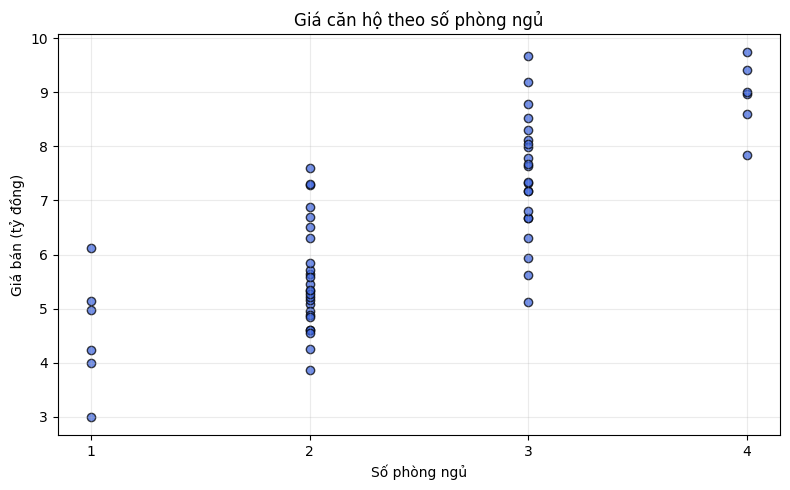

In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

duong_dan = Path("data/gia_nha.csv")
if not duong_dan.exists():
    duong_dan = Path("gia_nha.csv")

df = pd.read_csv(duong_dan)

plt.figure(figsize=(8, 5))
plt.scatter(
    df["so_phong"],
    df["gia"],
    color="royalblue",
    alpha=0.75,
    edgecolors="black"
)

plt.xlabel("Số phòng ngủ")
plt.ylabel("Giá bán (tỷ đồng)")
plt.title("Giá căn hộ theo số phòng ngủ")
plt.xticks(sorted(df["so_phong"].unique()))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig("bai2.png", dpi=150)

print(
    "Nhận xét: Nhìn chung, căn hộ có nhiều phòng ngủ hơn thường có "
    "giá cao hơn. Tuy nhiên, các mức giá vẫn phân tán nên số phòng "
    "không phải là yếu tố duy nhất quyết định giá."
)

plt.show()

# **Bài 3**

In [13]:
from pathlib import Path
import pandas as pd

duong_dan = Path("gia_nha.csv")
if not duong_dan.exists():
    duong_dan = Path("gia_nha.csv")

df = pd.read_csv(duong_dan)

# Đổi biến đầu vào từ diện tích sang tuổi nhà
x = df["tuoi_nha"].to_numpy()
y = df["gia"].to_numpy()

x_trung_binh = x.mean()
y_trung_binh = y.mean()

# Công thức bình phương tối thiểu
tu_so = ((x - x_trung_binh) * (y - y_trung_binh)).sum()
mau_so = ((x - x_trung_binh) ** 2).sum()

w = tu_so / mau_so
b = y_trung_binh - w * x_trung_binh

print("BAI 3: DUNG TUOI NHA DE DU DOAN GIA")
print(f"He so goc w = {w:.6f}")
print(f"He so chan b = {b:.6f}")
print()

if w < 0:
    print(
        "Nhận xét: w mang dấu âm, nghĩa là khi tuổi nhà tăng thêm "
        "một năm thì giá dự đoán có xu hướng giảm."
    )
    print(
        "Giải thích: Những căn hộ cũ hơn thường xuống cấp và có thời "
        "gian sử dụng còn lại ngắn hơn nên giá bán thường thấp hơn."
    )
else:
    print(
        "Nhận xét: w không mang dấu âm trên bộ dữ liệu này. "
        "Cần kiểm tra lại dữ liệu và biểu đồ phân tán."
    )

print(
    "Lưu ý: Đây chỉ là quan hệ thống kê trong bộ dữ liệu, "
    "không đủ để khẳng định quan hệ nhân quả."
)

BAI 3: DUNG TUOI NHA DE DU DOAN GIA
He so goc w = -0.037858
He so chan b = 6.983593

Nhận xét: w mang dấu âm, nghĩa là khi tuổi nhà tăng thêm một năm thì giá dự đoán có xu hướng giảm.
Giải thích: Những căn hộ cũ hơn thường xuống cấp và có thời gian sử dụng còn lại ngắn hơn nên giá bán thường thấp hơn.
Lưu ý: Đây chỉ là quan hệ thống kê trong bộ dữ liệu, không đủ để khẳng định quan hệ nhân quả.


# **Bước 3 làm thêm**

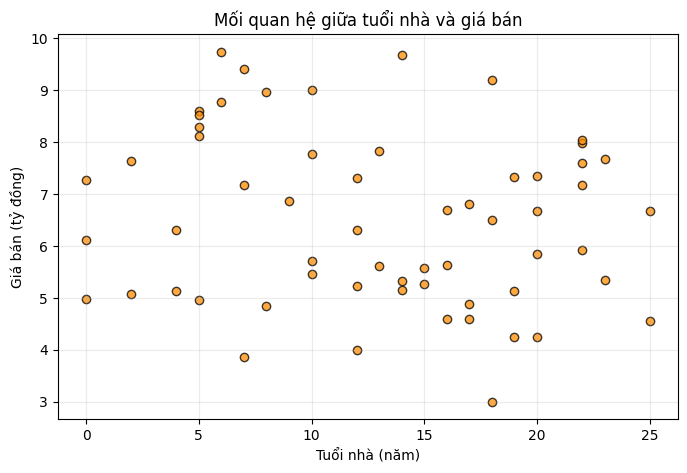

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("gia_nha.csv")

plt.figure(figsize=(8, 5))
plt.scatter(
    df["tuoi_nha"],
    df["gia"],
    color="darkorange",
    edgecolors="black",
    alpha=0.75
)

plt.xlabel("Tuổi nhà (năm)")
plt.ylabel("Giá bán (tỷ đồng)")
plt.title("Mối quan hệ giữa tuổi nhà và giá bán")
plt.grid(alpha=0.25)
plt.show()

# **Bước 4**

In [15]:
from pathlib import Path
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

duong_dan = Path("gia_nha.csv")
if not duong_dan.exists():
    duong_dan = Path("gia_nha.csv")

df = pd.read_csv(duong_dan)
y = df["gia"]

# Mô hình một biến dùng để đối chiếu
X_mot_bien = df[["dien_tich"]]

X_train_1, X_test_1, y_train_1, y_test_1 = train_test_split(
    X_mot_bien,
    y,
    test_size=0.2,
    random_state=42
)

mo_hinh_mot_bien = LinearRegression()
mo_hinh_mot_bien.fit(X_train_1, y_train_1)

du_doan_1 = mo_hinh_mot_bien.predict(X_test_1)
r2_mot_bien = r2_score(y_test_1, du_doan_1)

# Mô hình hai biến: diện tích và số phòng
X_hai_bien = df[["dien_tich", "so_phong"]]

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(
    X_hai_bien,
    y,
    test_size=0.2,
    random_state=42
)

mo_hinh_hai_bien = LinearRegression()
mo_hinh_hai_bien.fit(X_train_2, y_train_2)

du_doan_2 = mo_hinh_hai_bien.predict(X_test_2)
r2_hai_bien = r2_score(y_test_2, du_doan_2)

chenh_lech = r2_hai_bien - r2_mot_bien

print("BAI 4: THEM SO PHONG VAO MO HINH")
print(f"R2 cua mo hinh mot bien : {r2_mot_bien:.4f}")
print(f"R2 cua mo hinh hai bien : {r2_hai_bien:.4f}")
print(f"Muc thay doi R2         : {chenh_lech:+.4f}")
print()

if chenh_lech > 0.01:
    print(
        "Nhận xét: Thêm số phòng giúp mô hình cải thiện R2 khá rõ rệt, "
        "vì vậy đây là một biến đầu vào hữu ích."
    )
elif chenh_lech > 0:
    print(
        "Nhận xét: Thêm số phòng có làm R2 tăng, nhưng mức tăng khá nhỏ. "
        "Diện tích đã giải thích phần lớn sự thay đổi của giá."
    )
elif chenh_lech == 0:
    print(
        "Nhận xét: Thêm số phòng không làm thay đổi R2, "
        "vì vậy biến này chưa cung cấp thêm thông tin hữu ích."
    )
else:
    print(
        "Nhận xét: R2 giảm sau khi thêm số phòng. Trên tập kiểm tra này, "
        "việc thêm biến chưa giúp mô hình dự đoán tốt hơn."
    )

BAI 4: THEM SO PHONG VAO MO HINH
R2 cua mo hinh mot bien : 0.9622
R2 cua mo hinh hai bien : 0.9698
Muc thay doi R2         : +0.0075

Nhận xét: Thêm số phòng có làm R2 tăng, nhưng mức tăng khá nhỏ. Diện tích đã giải thích phần lớn sự thay đổi của giá.


# **Bài 5**

In [18]:
import numpy as np
import pandas as pd

# Đọc dữ liệu đã tải lên Colab
df = pd.read_csv("gia_nha.csv")

x_goc = df["dien_tich"].to_numpy()
y = df["gia"].to_numpy()

# Chuẩn hóa diện tích
x_trung_binh = x_goc.mean()
x_do_lech = x_goc.std()
x = (x_goc - x_trung_binh) / x_do_lech

# Lần 1 đặt 0.001
# Lần 2 đổi thành 1.02 rồi chạy lại
toc_do_hoc = 0.001

so_vong = 200
n = len(x)

w = 0.0
b = 0.0

for vong in range(1, so_vong + 1):
    y_du_doan = w * x + b
    chenh_lech = y_du_doan - y

    # Tính gradient
    grad_w = (2 / n) * (chenh_lech * x).sum()
    grad_b = (2 / n) * chenh_lech.sum()

    # Cập nhật w và b
    w -= toc_do_hoc * grad_w
    b -= toc_do_hoc * grad_b

    if vong in (1, 2, 5, 10, 25, 50, 100, 200):
        mse = (((w * x + b) - y) ** 2).mean()

        print(
            f"Vong {vong:3d}: "
            f"w = {w:.6f}, "
            f"b = {b:.6f}, "
            f"MSE = {mse:.6e}"
        )

# MSE sau vòng lặp thứ 200
mse_cuoi = (((w * x + b) - y) ** 2).mean()

print()
print(f"Toc do hoc: {toc_do_hoc}")
print(f"MSE tai vong 200: {mse_cuoi:.6e}")
print()

if toc_do_hoc == 0.001:
    print(
        "Giải thích: Tốc độ học 0.001 quá nhỏ nên mỗi lần cập nhật "
        "chỉ đi một bước rất ngắn. Sau 200 vòng, mô hình vẫn chưa "
        "đi tới điểm MSE nhỏ nhất."
    )

elif toc_do_hoc == 1.02:
    print(
        "Giải thích: Tốc độ học 1.02 quá lớn nên mỗi bước cập nhật "
        "nhảy qua điểm thấp nhất. Khoảng cách ngày càng lớn khiến "
        "MSE tăng mạnh và thuật toán bị phân kỳ."
    )

Vong   1: w = 0.003143, b = 0.012987, MSE = 4.463291e+01
Vong   2: w = 0.006279, b = 0.025947, MSE = 4.445527e+01
Vong   5: w = 0.015650, b = 0.064674, MSE = 4.392660e+01
Vong  10: w = 0.031144, b = 0.128704, MSE = 4.305948e+01
Vong  25: w = 0.076706, b = 0.316993, MSE = 4.055989e+01
Vong  50: w = 0.149667, b = 0.618511, MSE = 3.671349e+01
Vong 100: w = 0.285078, b = 1.178106, MSE = 3.008492e+01
Vong 200: w = 0.518434, b = 2.142465, MSE = 2.021752e+01

Toc do hoc: 0.001
MSE tai vong 200: 2.021752e+01

Giải thích: Tốc độ học 0.001 quá nhỏ nên mỗi lần cập nhật chỉ đi một bước rất ngắn. Sau 200 vòng, mô hình vẫn chưa đi tới điểm MSE nhỏ nhất.


# **Bài 6**

In [19]:
# Hệ số của mô hình một biến đã được tìm ở phần trước
w = 0.078367
b = 0.401752

DIEN_TICH_NHO_NHAT = 35.5
DIEN_TICH_LON_NHAT = 117.5


def du_doan_gia(dien_tich):
    """Dự đoán giá căn hộ từ diện tích, đơn vị kết quả là tỷ đồng."""

    if dien_tich < DIEN_TICH_NHO_NHAT or dien_tich > DIEN_TICH_LON_NHAT:
        print(
            f"CẢNH BÁO: Diện tích {dien_tich} m2 nằm ngoài vùng dữ liệu "
            f"từ {DIEN_TICH_NHO_NHAT} đến {DIEN_TICH_LON_NHAT} m2."
        )
        print("Kết quả này là ngoại suy và có thể không đáng tin cậy.")

    gia_du_doan = w * dien_tich + b
    return gia_du_doan


print("BAI 6: HAM DU DOAN GIA CO CANH BAO")
print()

for dien_tich in [60, 80, 200]:
    gia = du_doan_gia(dien_tich)
    print(f"Can {dien_tich} m2 -> du doan {gia:.3f} ty dong")
    print()

BAI 6: HAM DU DOAN GIA CO CANH BAO

Can 60 m2 -> du doan 5.104 ty dong

Can 80 m2 -> du doan 6.671 ty dong

CẢNH BÁO: Diện tích 200 m2 nằm ngoài vùng dữ liệu từ 35.5 đến 117.5 m2.
Kết quả này là ngoại suy và có thể không đáng tin cậy.
Can 200 m2 -> du doan 16.075 ty dong

